# Student Depression Classification

## 1. Problem statement

Build a binary classification model to predict the dataset's `depression` label using demographic, academic, and lifestyle-related features.

This is an educational prediction task. The dataset label is **not a clinical diagnosis**, and model predictions should not be interpreted as medical assessments.

## 2. Dataset

Indian Student Depression Dataset  
Target: `depression`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 1

## 3. Load and prepare the data

Normalize column names and categorical text. Convert sleep-duration ranges to their numeric midpoint. The identifier `id` is retained in the raw data for traceability but excluded from model features.

In [2]:
df = pd.read_csv('dataset/Student Depression Dataset.csv')

df.columns = (
    df.columns.str.lower()
    .str.replace(' ', '_')
    .str.replace('/', '_or_')
)

df = df.rename(columns={
    'have_you_ever_had_suicidal_thoughts_?': 'suicidal_thoughts'
})

categorical_columns = df.select_dtypes(include=['object', 'string']).columns
for col in categorical_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_', regex=False)

df['sleep_duration'] = (
    df['sleep_duration']
    .str.extract(r'(\d+)(?:-(\d+))?')
    .astype(float)
    .mean(axis=1)
)

df.head()

,id,gender,age,city,profession,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,sleep_duration,dietary_habits,degree,suicidal_thoughts,work_or_study_hours,financial_stress,family_history_of_mental_illness,depression
0,2,male,33.0,visakhapatnam,student,5.0,0.0,8.97,2.0,0.0,5.5,healthy,b.pharm,yes,3.0,1.0,no,1
1,8,female,24.0,bangalore,student,2.0,0.0,5.90,5.0,0.0,5.5,moderate,bsc,no,3.0,2.0,yes,0
2,26,male,31.0,srinagar,student,3.0,0.0,7.03,5.0,0.0,5.0,healthy,ba,no,9.0,1.0,yes,0
3,30,female,28.0,varanasi,student,3.0,0.0,5.59,2.0,0.0,7.5,moderate,bca,yes,4.0,5.0,yes,1
4,32,female,25.0,jaipur,student,4.0,0.0,8.13,3.0,0.0,5.5,moderate,m.tech,yes,1.0,1.0,no,0


In [3]:
df.shape, df.dtypes

((27901, 18),
 id                                    int64
 gender                                  str
 age                                 float64
 city                                    str
 profession                              str
 academic_pressure                   float64
 work_pressure                       float64
 cgpa                                float64
 study_satisfaction                  float64
 job_satisfaction                    float64
 sleep_duration                      float64
 dietary_habits                          str
 degree                                  str
 suicidal_thoughts                       str
 work_or_study_hours                 float64
 financial_stress                    float64
 family_history_of_mental_illness        str
 depression                            int64
 dtype: object)

In [4]:
categorical = df.select_dtypes(include=['object', 'string']).columns
for c in categorical:
    print(df[c].value_counts())
    print()

gender
male      15547
female    12354
Name: count, dtype: int64

city
kalyan                1570
srinagar              1372
hyderabad             1340
vasai-virar           1290
lucknow               1155
thane                 1139
ludhiana              1111
agra                  1094
surat                 1078
kolkata               1066
jaipur                1036
patna                 1007
visakhapatnam          969
pune                   968
ahmedabad              951
bhopal                 934
chennai                885
meerut                 825
rajkot                 816
delhi                  768
bangalore              767
ghaziabad              745
mumbai                 699
vadodara               694
varanasi               685
nagpur                 651
indore                 643
kanpur                 609
nashik                 547
faridabad              461
saanvi                   2
bhavna                   2
city                     2
harsha                   2
m.tech     

## 4. Train, validation, and test split

First, reserve 20% of the dataset as the untouched test set. Split the remaining 80% into a training set and a validation set. Use the training set to fit candidate models, the validation set to select hyperparameters, and keep the test set untouched until the final evaluation.

In [4]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df.depression
)

# Split the development data into train and validation sets.
df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df_full_train.depression
)

# Reset indices for clean positional indexing later.
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.depression.to_numpy()
y_val = df_val.depression.to_numpy()
y_full_train = df_full_train.depression.to_numpy()
y_test = df_test.depression.to_numpy()

print('Train:', df_train.shape)
print('Validation:', df_val.shape)
print('Full training data:', df_full_train.shape)
print('Test:', df_test.shape)

Train: (16740, 18)
Validation: (5580, 18)
Full training data: (22320, 18)
Test: (5581, 18)


In [29]:
df_full_train.to_csv('dataset/student-depression-full-train.csv', index=False)
df_test.to_csv('dataset/student-depression-test.csv', index=False)

## 5. Exploratory data analysis

EDA is performed on the training split only. A separate copy is imputed for analysis; the modeling data remains unchanged so preprocessing can be fitted using training data only.

In [5]:
eda_df = df_train.copy()

print('Missing values before imputation:')
display(eda_df.isna().sum().sort_values(ascending=False).head(10))

print('Duplicate rows:', eda_df.duplicated().sum())
print('Target distribution:')
display(eda_df.depression.value_counts().rename('count').to_frame())
display((eda_df.depression.value_counts(normalize=True) * 100).round(2).rename('percent').to_frame())

Missing values before imputation:


sleep_duration       13
financial_stress      2
gender                0
id                    0
age                   0
city                  0
work_pressure         0
cgpa                  0
profession            0
academic_pressure     0
dtype: int64

Duplicate rows: 0
Target distribution:


,count
depression,
1,9801
0,6939


,percent
depression,
1,58.55
0,41.45


In [6]:
impute_columns = ['sleep_duration', 'financial_stress']
eda_imputer = SimpleImputer(strategy='most_frequent')
eda_df[impute_columns] = eda_imputer.fit_transform(eda_df[impute_columns])

numerical = eda_df.select_dtypes(include='number').columns.drop(
    ['id', 'depression'], errors='ignore'
)
categorical = eda_df.select_dtypes(include=['object', 'string']).columns

display(eda_df[numerical].describe().round(2))
display(eda_df[categorical].nunique().sort_values(ascending=False).to_frame('unique_values'))

,age,academic_pressure,work_pressure,cgpa,study_satisfaction,job_satisfaction,sleep_duration,work_or_study_hours,financial_stress
count,16740.00,16740.00,16740.00,16740.00,16740.00,16740.00,16740.00,16740.00,16740.00
mean,25.84,3.14,0.00,7.65,2.94,0.00,6.42,7.18,3.16
std,4.90,1.38,0.06,1.48,1.36,0.06,1.28,3.71,1.44
min,18.00,0.00,0.00,0.00,0.00,0.00,5.00,0.00,1.00
25%,21.00,2.00,0.00,6.27,2.00,0.00,5.00,4.00,2.00
50%,25.00,3.00,0.00,7.77,3.00,0.00,5.50,8.00,3.00
75%,30.00,4.00,0.00,8.92,4.00,0.00,7.50,10.00,4.00
max,59.00,5.00,5.00,10.00,5.00,4.00,8.00,12.00,5.00


,unique_values
city,46
degree,28
profession,13
dietary_habits,4
gender,2
suicidal_thoughts,2
family_history_of_mental_illness,2


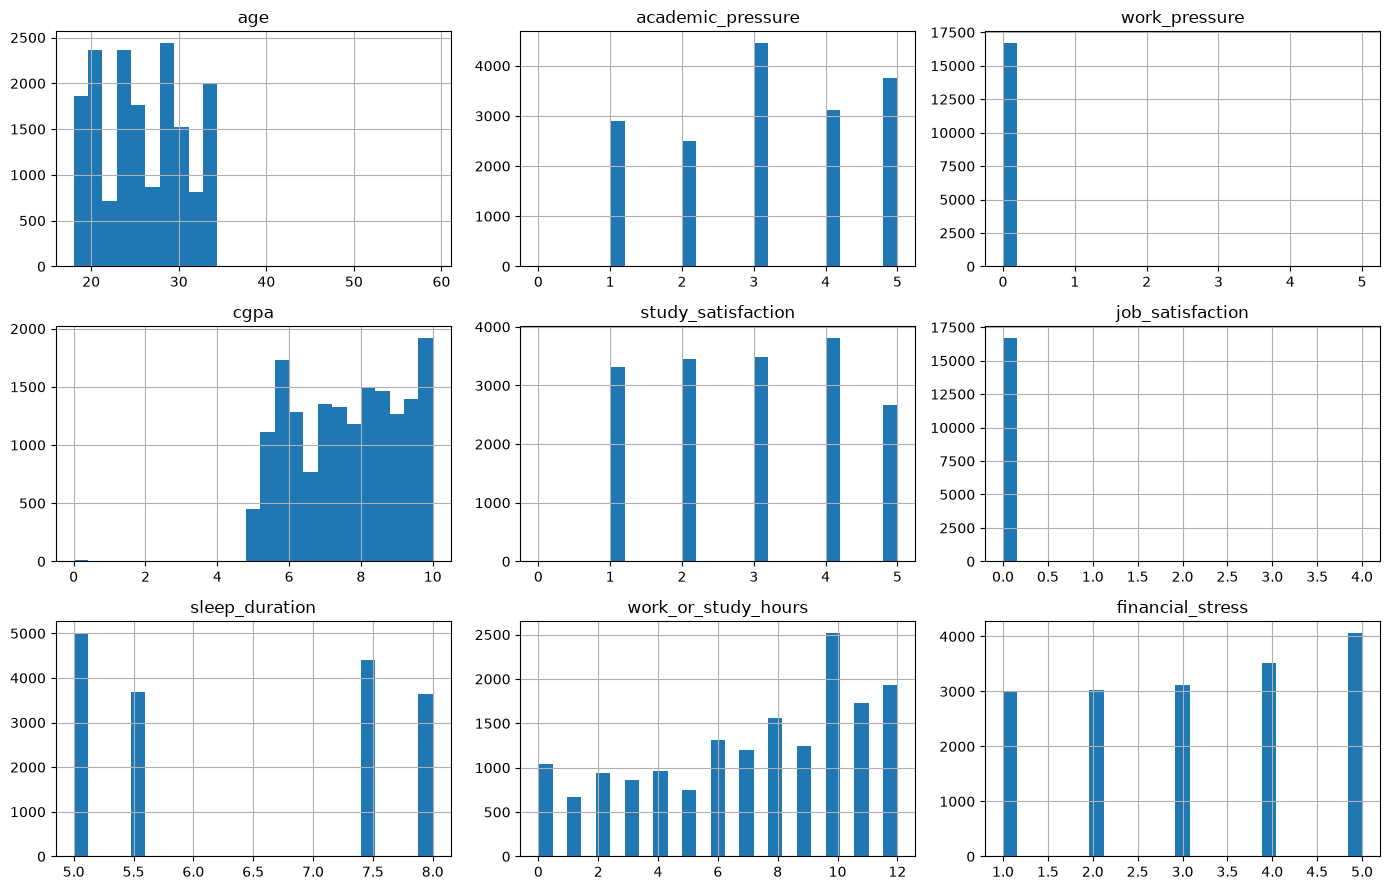

In [7]:
eda_df[numerical].hist(figsize=(14, 9), bins=25)
plt.tight_layout()
plt.show()

In [8]:
display(eda_df.groupby('depression')[numerical].mean().T.round(2))

depression,0,1
age,27.11,24.93
academic_pressure,2.34,3.70
work_pressure,0.00,0.00
cgpa,7.59,7.68
study_satisfaction,3.20,2.76
job_satisfaction,0.00,0.00
sleep_duration,6.53,6.34
work_or_study_hours,6.25,7.84
financial_stress,2.53,3.60


## Feature importance: Mutual information
Mutual information - concept from information theory, it tells us how much we can learn about one variable if we know the value of another

In [9]:
from sklearn.metrics import mutual_info_score

In [10]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.depression)

In [11]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

suicidal_thoughts                   0.156703
dietary_habits                      0.021787
degree                              0.009320
city                                0.003899
family_history_of_mental_illness    0.001581
profession                          0.000355
gender                              0.000007
dtype: float64

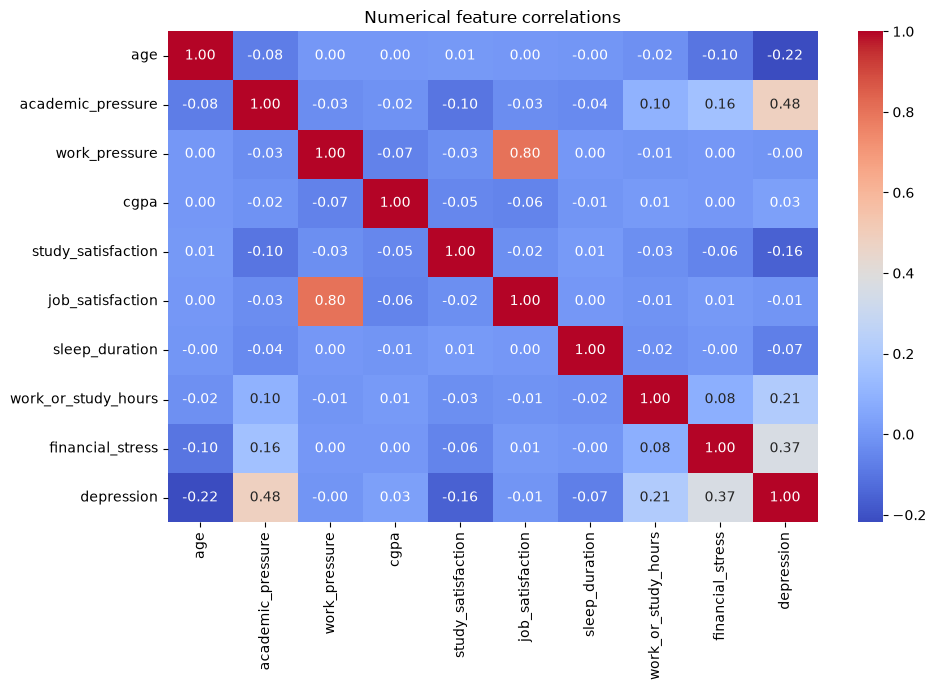

In [12]:
correlation = eda_df[list(numerical) + ['depression']].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Numerical feature correlations')
plt.tight_layout()
plt.show()

In [13]:
for col in categorical:
    print(f'{col} — top categories')
    display(eda_df[col].value_counts().head(10).to_frame('count'))

gender — top categories


,count
gender,
male,9315
female,7425


city — top categories


,count
city,
kalyan,925
srinagar,850
hyderabad,796
vasai-virar,754
lucknow,703
thane,689
ludhiana,667
agra,660
kolkata,646


profession — top categories


,count
profession,
student,16717
architect,6
digital_marketer,3
teacher,3
chef,2
doctor,2
ux/ui_designer,1
educational_consultant,1
content_writer,1


... (4 outputs left out)

suicidal_thoughts — top categories


,count
suicidal_thoughts,
yes,10609
no,6131


family_history_of_mental_illness — top categories


,count
family_history_of_mental_illness,
no,8686
yes,8054


In [14]:
for col in ['gender', 'dietary_habits', 'suicidal_thoughts',
            'family_history_of_mental_illness']:
    if col in eda_df.columns:
        print(f'\nDepression proportion by {col}')
        display(pd.crosstab(
            eda_df[col], eda_df['depression'], normalize='index'
        ).round(3))


Depression proportion by gender


depression,0,1
gender,,
female,0.419,0.581
male,0.411,0.589



Depression proportion by dietary_habits


depression,0,1
dietary_habits,,
healthy,0.541,0.459
moderate,0.438,0.562
others,0.125,0.875
unhealthy,0.300,0.700



Depression proportion by suicidal_thoughts


depression,0,1
suicidal_thoughts,,
no,0.768,0.232
yes,0.210,0.790



Depression proportion by family_history_of_mental_illness


depression,0,1
family_history_of_mental_illness,,
no,0.442,0.558
yes,0.385,0.615


### EDA Summary

The EDA provided an overview of the target distribution, missing values, feature distributions, and relationships between individual features and the target variable, `depression`. The analysis helped identify patterns, potential data-quality issues, and features that may be useful for predicting the target.

Associations observed during EDA should not be interpreted as causal relationships. High-cardinality categorical features and categories with very few observations should also be interpreted cautiously, as their observed patterns may not be representative.

**Exclusion of `suicidal_thoughts`:**

The `suicidal_thoughts` feature showed a strong association with the target variable. However, we decided to exclude it from model training for two main reasons:

- **Ethical considerations:** Suicidal thoughts are highly sensitive personal information. Using this feature in a student prediction model raises privacy and ethical concerns.
- **Model reliability and practical applicability:** Its strong association with the target could allow the model to rely heavily on a closely related indicator rather than learning broader patterns from academic, lifestyle, and demographic features. It may also not be appropriate or available in the intended real-world use case.

Therefore, `suicidal_thoughts` was excluded from all subsequent feature selection, hyperparameter tuning, cross-validation, and model training. The remaining features were used to evaluate how effectively the models could predict the target without relying on this sensitive information.

These decisions help keep the modelling approach more ethically appropriate and focused on the intended prediction task.

## 6. Preprocessing and model functions

For each experiment, fit the imputer and vectorizer on the training data, then apply the fitted transformations to validation data. Exclude `id` and `depression` from model features. Logistic Regression additionally uses `MaxAbsScaler`.

In [15]:
def fit_preprocessor(df_train):
    df_train = df_train.copy()

    imputer = SimpleImputer(strategy='most_frequent')
    impute_columns = ['sleep_duration', 'financial_stress']
    df_train[impute_columns] = imputer.fit_transform(df_train[impute_columns])

    drop_columns = ['id', 'depression', 'suicidal_thoughts']
    df_train = df_train.drop(columns=drop_columns, errors='ignore')

    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(df_train.to_dict(orient='records'))

    return dv, imputer, X_train


def transform_features(df, dv, imputer):
    df = df.copy()

    impute_columns = ['sleep_duration', 'financial_stress']
    df[impute_columns] = imputer.transform(df[impute_columns])

    df = df.drop(columns=['id', 'depression'], errors='ignore')
    return dv.transform(df.to_dict(orient='records'))

## 7. Logistic Regression: validation-based hyperparameter tuning

Tune the regularization parameter `C` using the training and validation sets. Select the value with the highest validation ROC-AUC. The validation set is used for hyperparameter selection; it is not used to fit preprocessing or model parameters.

In [16]:
def train_logistic_regression(df_train, y_train, C=1.0):
    dv, imputer, X_train = fit_preprocessor(df_train)

    scaler = MaxAbsScaler()
    X_train = scaler.fit_transform(X_train)

    model = LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    return dv, imputer, scaler, model


def predict_logistic_regression(df, dv, imputer, scaler, model):
    X = transform_features(df, dv, imputer)
    X = scaler.transform(X)
    return model.predict_proba(X)[:, 1]

In [17]:
lr_val_results = []

for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]:
    dv, imputer, scaler, lr = train_logistic_regression(
        df_train, y_train, C=C
    )
    val_predictions = predict_logistic_regression(
        df_val, dv, imputer, scaler, lr
    )
    val_auc = roc_auc_score(y_val, val_predictions)

    lr_val_results.append({'C': C, 'validation_auc': val_auc})

lr_val_results = pd.DataFrame(lr_val_results).sort_values(
    'validation_auc', ascending=False
).reset_index(drop=True)

display(lr_val_results)
best_C = float(lr_val_results.iloc[0]['C'])
print('Selected C:', best_C)

,C,validation_auc
0,1.000,0.865512
1,5.000,0.865459
2,0.500,0.865434
3,10.000,0.865390
4,0.100,0.864318
5,0.010,0.861008
6,0.001,0.847334


Selected C: 1.0


## 8. Decision Tree: sequential validation-based tuning

Tune the tree in two stages. First, select `max_depth` while keeping `min_samples_leaf=1`. Then fix the selected depth and tune `min_samples_leaf`. Both stages use the same training and validation sets.

In [18]:
def train_decision_tree(df_train, y_train, max_depth=7, min_samples_leaf=1):
    dv, imputer, X_train = fit_preprocessor(df_train)

    model = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)

    return dv, imputer, model


def predict_decision_tree(df, dv, imputer, model):
    X = transform_features(df, dv, imputer)
    return model.predict_proba(X)[:, 1]

In [19]:
# Stage 1: select max_depth with min_samples_leaf fixed at 1.
dt_depth_results = []

for depth in [1, 2, 3, 5, 7, 10, 15, 20, None]:
    dv, imputer, dt = train_decision_tree(
        df_train, y_train,
        max_depth=depth,
        min_samples_leaf=1
    )
    val_predictions = predict_decision_tree(df_val, dv, imputer, dt)
    dt_depth_results.append({
        'max_depth': depth,
        'validation_auc': roc_auc_score(y_val, val_predictions)
    })

dt_depth_results = pd.DataFrame(dt_depth_results).sort_values(
    'validation_auc', ascending=False
).reset_index(drop=True)

display(dt_depth_results)

,max_depth,validation_auc
0,7.0,0.835533
1,5.0,0.830735
2,3.0,0.802862
3,10.0,0.792917
4,2.0,0.771726
5,15.0,0.706102
6,1.0,0.696706
7,NaN,0.694309
8,20.0,0.691663


In [20]:
# Stage 2: select min_samples_leaf using the selected max_depth.
dt_leaf_results = []

for leaf in [1, 2, 5, 10, 15, 20, 30, 50, 100]:
    dv, imputer, dt = train_decision_tree(
        df_train, y_train,
        max_depth=7,
        min_samples_leaf=leaf
    )
    val_predictions = predict_decision_tree(df_val, dv, imputer, dt)
    dt_leaf_results.append({
        'max_depth': 7,
        'min_samples_leaf': leaf,
        'validation_auc': roc_auc_score(y_val, val_predictions)
    })

dt_leaf_results = pd.DataFrame(dt_leaf_results).sort_values(
    'validation_auc', ascending=False
).reset_index(drop=True)

display(dt_leaf_results)

,max_depth,min_samples_leaf,validation_auc
0,7,50,0.841002
1,7,30,0.840137
2,7,20,0.840090
3,7,15,0.839619
4,7,10,0.839197
5,7,5,0.838716
6,7,100,0.838602
7,7,2,0.836931
8,7,1,0.835533


## 9. Random Forest: sequential validation-based tuning

Tune the Random Forest hyperparameters sequentially using the validation set:
1. Select `n_estimators`: Test different values while keeping `max_depth=None` and `min_samples_leaf=1` at their defaults.
2. Select `max_depth`: Fix `n_estimators=200` and `min_samples_leaf=1`, then evaluate different maximum depths.
3. Select `min_samples_leaf`: Keep `n_estimators=200` and the selected `max_depth` fixed, then test different leaf sizes.
Use validation ROC-AUC to select the best value at each stage.

In [21]:
rf_n_estimators_results = []

for n_estimators in [50, 100, 150, 200, 300, 500]:
    dv, imputer, X_train = fit_preprocessor(df_train)
    X_val = transform_features(df_val, dv, imputer)

    rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=None,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    val_predictions = rf.predict_proba(X_val)[:, 1]

    rf_n_estimators_results.append({
        'n_estimators': n_estimators,
        'validation_auc': roc_auc_score(y_val, val_predictions)
    })

rf_n_estimators_results = pd.DataFrame(rf_n_estimators_results).sort_values(
    'validation_auc', ascending=False
).reset_index(drop=True)
display(rf_n_estimators_results)

,n_estimators,validation_auc
0,500,0.862487
1,300,0.862136
2,200,0.860635
3,150,0.859417
4,100,0.858318
5,50,0.854813


In [22]:
best_n_estimators = rf_n_estimators_results.iloc[0]['n_estimators']
print('Selected Random Forest best_n_estimators:', best_n_estimators)

Selected Random Forest best_n_estimators: 500.0


In [23]:
rf_depth_results = []
n_estimators = 500

for depth in [3, 5, 7, 10, 15, None]:
    dv, imputer, X_train = fit_preprocessor(df_train)
    X_val = transform_features(df_val, dv, imputer)

    rf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=depth,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    val_predictions = rf.predict_proba(X_val)[:, 1]

    rf_depth_results.append({
        'max_depth': depth,
        'validation_auc': roc_auc_score(y_val, val_predictions)
    })

rf_depth_results = pd.DataFrame(rf_depth_results).sort_values(
    'validation_auc', ascending=False
).reset_index(drop=True)
display(rf_depth_results)
best_rf_depth = rf_depth_results.iloc[0]['max_depth']
print('Selected Random Forest max_depth:', best_rf_depth)

,max_depth,validation_auc
0,15.0,0.865221
1,10.0,0.862943
2,NaN,0.862487
3,7.0,0.858396
4,5.0,0.855136
5,3.0,0.848497


Selected Random Forest max_depth: 15.0


In [24]:
# Stage 2: select min_samples_leaf using the selected max_depth.
rf_leaf_results = []

for leaf in [1, 2, 5, 10, 15, 20, 30, 50]:
    dv, imputer, X_train = fit_preprocessor(df_train)
    X_val = transform_features(df_val, dv, imputer)

    rf = RandomForestClassifier(
        n_estimators=500,
        max_depth=15,
        min_samples_leaf=leaf,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    val_predictions = rf.predict_proba(X_val)[:, 1]

    rf_leaf_results.append({
        'max_depth': best_rf_depth,
        'min_samples_leaf': leaf,
        'validation_auc': roc_auc_score(y_val, val_predictions)
    })

rf_leaf_results = pd.DataFrame(rf_leaf_results).sort_values(
    'validation_auc', ascending=False
).reset_index(drop=True)
display(rf_leaf_results)
best_rf_leaf = int(rf_leaf_results.iloc[0]['min_samples_leaf'])

,max_depth,min_samples_leaf,validation_auc
0,15.0,2,0.865784
1,15.0,1,0.865221
2,15.0,5,0.864955
3,15.0,10,0.864631
4,15.0,15,0.863485
5,15.0,20,0.863284
6,15.0,30,0.861511
7,15.0,50,0.859065


## 10. Compare selected configurations using 5-fold cross-validation

After validation-based hyperparameter tuning, evaluate each model family with its selected configuration using 5-fold Stratified Cross-Validation on the **training split only**. Use identical folds for all three models. Preprocessing is refitted independently inside every fold.

The validation set has served its purpose in parameter selection. The test set remains untouched. The `full training` dataset will only be used after the final model family and parameters have been selected.

In [25]:
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

selected_configs = {
    'Logistic Regression': {'C': 1},
    'Decision Tree': {
        'max_depth': 7,
        'min_samples_leaf': 50
    },
    'Random Forest': {
        'n_estimators': 500,
        'max_depth': 15,
        'min_samples_leaf': 2
    }
}

cv_results = []

for model_name, params in selected_configs.items():
    fold_scores = []

    for train_idx, val_idx in kfold.split(df_train, y_train):
        df_train_fold = df_train.iloc[train_idx]
        df_val_fold = df_train.iloc[val_idx]
        y_train_fold = y_train[train_idx]
        y_val_fold = y_train[val_idx]

        dv, imputer, X_train = fit_preprocessor(df_train_fold)
        X_val = transform_features(df_val_fold, dv, imputer)

        if model_name == 'Logistic Regression':
            scaler = MaxAbsScaler()
            X_train = scaler.fit_transform(X_train)
            X_val = scaler.transform(X_val)
            model = LogisticRegression(
                C=params['C'], max_iter=1000, random_state=RANDOM_STATE
            )
        elif model_name == 'Decision Tree':
            model = DecisionTreeClassifier(
                max_depth=params['max_depth'],
                min_samples_leaf=params['min_samples_leaf'],
                random_state=RANDOM_STATE
            )
        else:
            model = RandomForestClassifier(
                n_estimators=params['n_estimators'],
                max_depth=params['max_depth'],
                min_samples_leaf=params['min_samples_leaf'],
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

        model.fit(X_train, y_train_fold)
        fold_predictions = model.predict_proba(X_val)[:, 1]
        fold_scores.append(roc_auc_score(y_val_fold, fold_predictions))

    cv_results.append({
        'model': model_name,
        'parameters': str(params),
        'mean_auc': np.mean(fold_scores),
        'std_auc': np.std(fold_scores)
    })

model_comparison = pd.DataFrame(cv_results).sort_values(
    'mean_auc', ascending=False
).reset_index(drop=True)
display(model_comparison)

,model,parameters,mean_auc,std_auc
0,Logistic Regression,{'C': 1},0.870407,0.002775
1,Random Forest,"{'n_estimators': 500, 'max_depth': 15, 'min_sa...",0.866941,0.002990
2,Decision Tree,"{'max_depth': 7, 'min_samples_leaf': 50}",0.845861,0.002677


### Final model selection

Select the model with the highest mean 5-fold cross-validation ROC-AUC using the selected hyperparameters. Logistic Regression is the intended final choice if it ranks first in the comparison above. If another model has the higher mean AUC, follow the measured results rather than forcing the selection.

In [26]:
selected_model_name = model_comparison.iloc[0]['model']
print('Selected model:', selected_model_name)
print('Selected parameters:', model_comparison.iloc[0]['parameters'])
print(
    '5-fold CV ROC-AUC: '
    f"{model_comparison.iloc[0]['mean_auc']:.3f} "
    f"+- {model_comparison.iloc[0]['std_auc']:.3f}"
)

Selected model: Logistic Regression
Selected parameters: {'C': 1}
5-fold CV ROC-AUC: 0.870 +- 0.003


## 11. Train the selected model on the full training data and evaluate the test set

Only after selecting the model family and its hyperparameters, combine the training and validation data (`df_full_train`) to fit the final model. Evaluate it once on the untouched test set.

In [27]:
if selected_model_name != 'Logistic Regression':
    raise ValueError(
        'This final-training cell is written for Logistic Regression. '
        'Update it if cross-validation selects a different model.'
    )

final_dv, final_imputer, final_scaler, final_model = train_logistic_regression(
    df_full_train,
    y_full_train,
    C=best_C
)

test_predictions = predict_logistic_regression(
    df_test,
    final_dv,
    final_imputer,
    final_scaler,
    final_model
)

test_auc = roc_auc_score(y_test, test_predictions)
print(f'Test ROC-AUC: {test_auc:.3f}')

Test ROC-AUC: 0.875


Test accuracy: 0.803
              precision    recall  f1-score   support

           0       0.77      0.74      0.76      2313
           1       0.82      0.85      0.83      3268

    accuracy                           0.80      5581
   macro avg       0.80      0.79      0.80      5581
weighted avg       0.80      0.80      0.80      5581



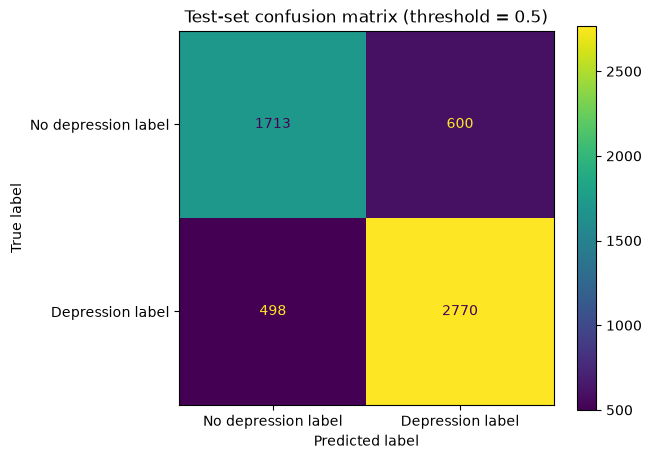

In [28]:
test_labels = (test_predictions >= 0.5).astype(int)

print(f'Test accuracy: {accuracy_score(y_test, test_labels):.3f}')
print(classification_report(y_test, test_labels, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_labels, display_labels=['No depression label', 'Depression label']
)
plt.title('Test-set confusion matrix (threshold = 0.5)')
plt.tight_layout()
plt.show()

## 12. Conclusion

Report the hyperparameters selected on the validation set, the 5-fold cross-validation ROC-AUC and standard deviation for each selected model configuration, the final selected model, and its held-out test ROC-AUC. Discuss limitations such as possible label noise, class imbalance, sensitive predictors, and the fact that the dataset label is not a clinical diagnosis.